# E-commerce sales analysis

Cleaning and exploring 5,000 **synthetic** sales records with pandas. The data is simulated, not from a real business.

### 1. Load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Upload ecommerce_sales_synthetic.csv to Colab before running.
df = pd.read_csv("ecommerce_sales_synthetic.csv")
print(df.shape)
df.head()


(5015, 10)


,order_id,customer_id,order_date,category,product,quantity,unit_price,region,payment_method,order_status
0,ORD00001,CUST0730,2025-11-27,Electronics,Headphones,2,1349.09,North,UPI,Completed
1,ORD00002,CUST0773,2025-07-18,Fashion,Cap,1,367.27,East,UPI,Completed
2,ORD00003,CUST0321,2025-11-14,Electronics,Wireless Mouse,1,795.81,East,UPI,Returned
3,ORD00004,CUST0968,2025-10-10,Fashion,Backpack,2,1351.61,East,UPI,Completed
4,ORD00005,CUST0029,2025-02-02,Fashion,Backpack,1,1436.03,North,UPI,Completed


### 2. Look at the data

In [3]:
print(df.columns)
print(df.info())
print(df.head(10))


Index(['order_id', 'customer_id', 'order_date', 'category', 'product',
       'quantity', 'unit_price', 'region', 'payment_method', 'order_status'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5015 entries, 0 to 5014
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        5015 non-null   object 
 1   customer_id     5015 non-null   object 
 2   order_date      5015 non-null   object 
 3   category        5015 non-null   object 
 4   product         5015 non-null   object 
 5   quantity        5015 non-null   int64  
 6   unit_price      5015 non-null   float64
 7   region          4955 non-null   object 
 8   payment_method  4980 non-null   object 
 9   order_status    5015 non-null   object 
dtypes: float64(1), int64(1), object(8)
memory usage: 391.9+ KB
None
   order_id customer_id  order_date     category         product  quantity  \
0  ORD00001    CUST0730  2025-11-27

In [4]:
# Missing values in each column
print(df.isnull().sum())

# Repeated rows
print("Duplicate rows:", df.duplicated().sum())

# Order types
print(df["order_status"].value_counts())


order_id           0
customer_id        0
order_date         0
category           0
product            0
quantity           0
unit_price         0
region            60
payment_method    35
order_status       0
dtype: int64
Duplicate rows: 15
order_status
Completed    4408
Returned      312
Cancelled     295
Name: count, dtype: int64


### 3. Clean the data

In [5]:
sales = df.copy()

# Remove exact duplicate rows
sales = sales.drop_duplicates()
print("Rows after duplicates:", len(sales))


Rows after duplicates: 5000


In [ ]:
# Fill missing labels
sales["region"] = sales["region"].fillna("Unknown")
sales["payment_method"] = sales["payment_method"].fillna("Unknown")

# Convert the date column
sales["order_date"] = pd.to_datetime(sales["order_date"], errors="coerce")

print(sales.isnull().sum())


order_id          0
customer_id       0
order_date        0
category          0
product           0
quantity          0
unit_price        0
region            0
payment_method    0
order_status      0
dtype: int64


In [ ]:
# Find records with invalid quantity or price
bad_rows = sales[(sales["quantity"] <= 0) | (sales["unit_price"] <= 0)]
print("Invalid price/quantity rows:", len(bad_rows))
print(bad_rows.head())


Invalid price/quantity rows: 20
     order_id customer_id order_date  ... region payment_method  order_status
22   ORD00023    CUST0005 2025-12-09  ...  South            UPI     Cancelled
32   ORD00033    CUST0487 2025-06-10  ...  North            UPI     Completed
478  ORD00479    CUST0155 2025-09-20  ...   West            COD     Completed
860  ORD00861    CUST1029 2025-10-16  ...  North           Card     Completed
897  ORD00898    CUST0101 2025-04-19  ...  North            COD     Completed

[5 rows x 10 columns]


In [ ]:
# Remove invalid records and missing dates
sales = sales[sales["quantity"] > 0]
sales = sales[sales["unit_price"] > 0]
sales = sales.dropna(subset=["order_date"])

# Calculate order value
sales["sales_amount"] = sales["quantity"] * sales["unit_price"]
sales["month"] = sales["order_date"].dt.to_period("M").astype(str)

print("Cleaned rows:", len(sales))
sales.head()


Cleaned rows: 4980


,order_id,customer_id,order_date,category,product,quantity,unit_price,region,payment_method,order_status,sales_amount,month
0,ORD00001,CUST0730,2025-11-27,Electronics,Headphones,2,1349.09,North,UPI,Completed,2698.18,2025-11
1,ORD00002,CUST0773,2025-07-18,Fashion,Cap,1,367.27,East,UPI,Completed,367.27,2025-07
2,ORD00003,CUST0321,2025-11-14,Electronics,Wireless Mouse,1,795.81,East,UPI,Returned,795.81,2025-11
3,ORD00004,CUST0968,2025-10-10,Fashion,Backpack,2,1351.61,East,UPI,Completed,2703.22,2025-10
4,ORD00005,CUST0029,2025-02-02,Fashion,Backpack,1,1436.03,North,UPI,Completed,1436.03,2025-02


In [ ]:
# Compare data size before and after cleaning
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(sales))
print("Rows removed:", len(df) - len(sales))

Rows before cleaning: 5015
Rows after cleaning: 4980
Rows removed: 35


### 4. Completed orders

In [ ]:
# Count only completed orders for sales analysis
completed = sales[sales["order_status"] == "Completed"].copy()

print("Completed orders:", len(completed))
print("Total sales value:", round(completed["sales_amount"].sum(), 2))


Completed orders: 4377
Total sales value: 5725406.83


### 5. Business questions

**Q1. How did sales change each month?**

In [ ]:
monthly_sales = completed.groupby("month")["sales_amount"].sum()
monthly_sales = monthly_sales.sort_index()
print(monthly_sales)


month
2025-01    300568.78
2025-02    289468.40
2025-03    420734.81
2025-04    411124.16
2025-05    463303.99
2025-06    391244.81
2025-07    461850.58
2025-08    523519.53
2025-09    494315.75
2025-10    578723.30
2025-11    682720.12
2025-12    707832.60
Name: sales_amount, dtype: float64


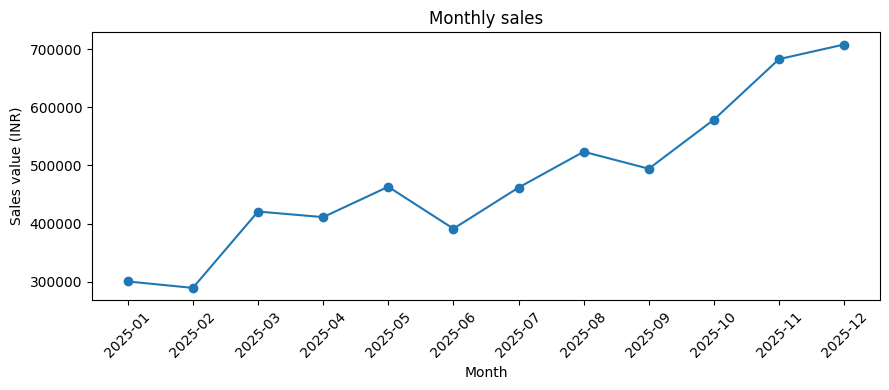

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly sales")
plt.xlabel("Month")
plt.ylabel("Sales value (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
print("Highest sales month:", monthly_sales.idxmax())
print("Sales in that month: INR", round(monthly_sales.max(), 2))

Highest sales month: 2025-12
Sales in that month: INR 707832.6


**Q2. Which product categories made the most sales?**

In [ ]:
category_sales = completed.groupby("category")["sales_amount"].sum()
category_sales = category_sales.sort_values(ascending=False)
print(category_sales)


category
Electronics    2366703.07
Fashion        1873719.46
Home           1126164.90
Books           358819.40
Name: sales_amount, dtype: float64


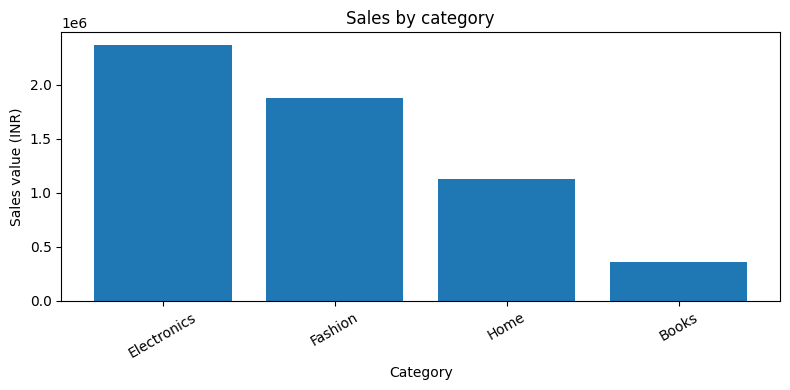

In [ ]:
plt.figure(figsize=(8, 4))
plt.bar(category_sales.index, category_sales.values)
plt.title("Sales by category")
plt.xlabel("Category")
plt.ylabel("Sales value (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:
print("Top category:", category_sales.idxmax())
print("Category sales: INR", round(category_sales.max(), 2))

Top category: Electronics
Category sales: INR 2366703.07


**Q3. Which region made the most sales?**

In [ ]:
region_sales = completed.groupby("region")["sales_amount"].sum()
region_sales = region_sales.sort_values(ascending=False)
print(region_sales)


region
East       1460346.29
West       1452549.15
South      1377682.17
North      1377109.15
Unknown      57720.07
Name: sales_amount, dtype: float64


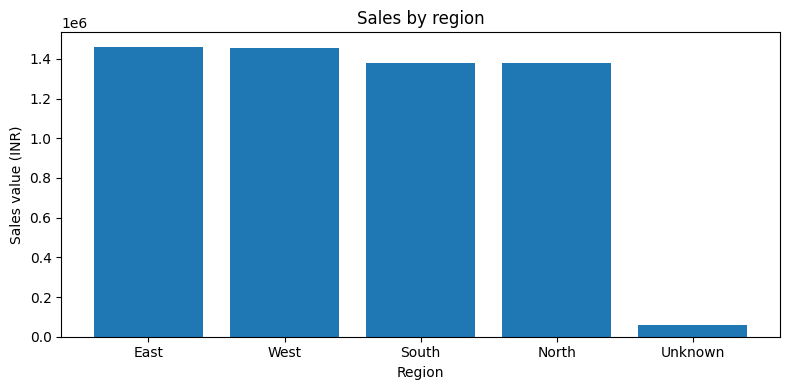

In [ ]:
plt.figure(figsize=(8, 4))
plt.bar(region_sales.index, region_sales.values)
plt.title("Sales by region")
plt.xlabel("Region")
plt.ylabel("Sales value (INR)")
plt.tight_layout()
plt.show()


In [ ]:
print("Top region:", region_sales.idxmax())
print("Regional sales: INR", round(region_sales.max(), 2))

Top region: East
Regional sales: INR 1460346.29


**Q4. How many customers placed more than one completed order?**

In [ ]:
orders_per_customer = completed.groupby("customer_id")["order_id"].nunique()
repeat_customers = (orders_per_customer >= 2).sum()
total_customers = len(orders_per_customer)

print("Customers with completed orders:", total_customers)
print("Repeat customers:", repeat_customers)
print("Repeat customer %:", round(repeat_customers / total_customers * 100, 2))


Customers with completed orders: 1077
Repeat customers: 1003
Repeat customer %: 93.13


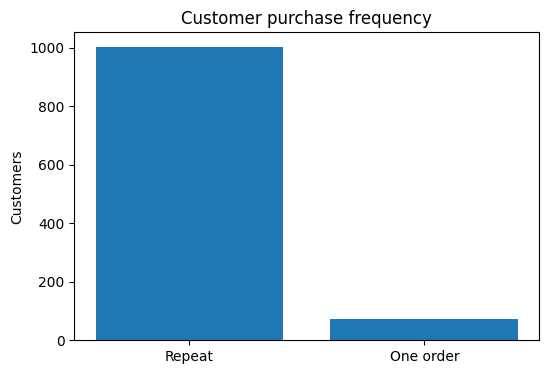

In [ ]:
labels = ["Repeat", "One order"]
counts = [repeat_customers, total_customers - repeat_customers]

plt.figure(figsize=(6, 4))
plt.bar(labels, counts)
plt.title("Customer purchase frequency")
plt.ylabel("Customers")
plt.show()


**Q5. Which categories had the highest percentage of returned orders?**

In [ ]:
# Return rate among completed or returned orders only
finished = sales[sales["order_status"].isin(["Completed", "Returned"])].copy()
finished["returned"] = np.where(finished["order_status"] == "Returned", 1, 0)

return_rate = finished.groupby("category")["returned"].mean() * 100
return_rate = return_rate.sort_values(ascending=False)
print(return_rate.round(2))
print("Highest return-rate category:", return_rate.idxmax())

category
Books          7.25
Home           6.97
Electronics    6.92
Fashion        5.90
Name: returned, dtype: float64
Highest return-rate category: Books


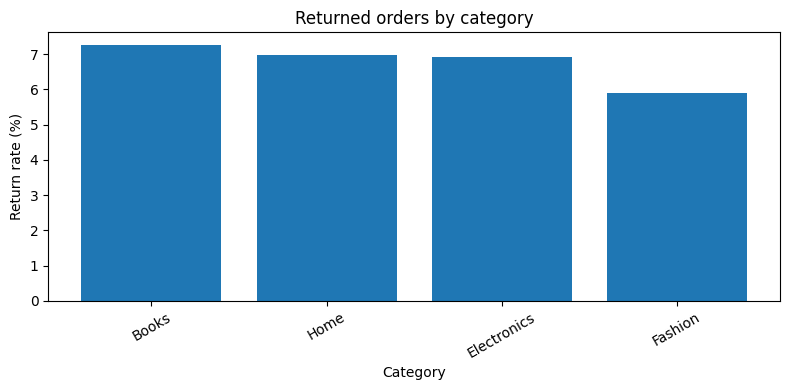

In [ ]:
plt.figure(figsize=(8, 4))
plt.bar(return_rate.index, return_rate.values)
plt.title("Returned orders by category")
plt.xlabel("Category")
plt.ylabel("Return rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Extra: What was the average completed order value?**

In [ ]:
# Each row represents one order in this synthetic dataset
average_order_value = completed["sales_amount"].mean()
print("Average completed order value: INR", round(average_order_value, 2))

Average completed order value: INR 1308.07


### 6. Summary and business ideas

In [ ]:
print("Total completed sales:", round(completed["sales_amount"].sum(), 2))
print("Average completed order:", round(completed["sales_amount"].mean(), 2))
print("Best sales month:", monthly_sales.idxmax())
print("Top category:", category_sales.idxmax())
print("Top region:", region_sales.idxmax())
print("Highest return rate category:", return_rate.idxmax())


Total completed sales: 5725406.83
Average completed order: 1308.07
Best sales month: 2025-12
Top category: Electronics
Top region: East
Highest return rate category: Books


These are ideas to investigate, **not proven causes**. All findings are based on synthetic data. Return rate uses only Completed and Returned orders.

### 7. Save cleaned data

In [ ]:
sales.to_csv("cleaned_ecommerce_sales.csv", index=False)
print("Saved cleaned_ecommerce_sales.csv")


Saved cleaned_ecommerce_sales.csv
